# ResNet18: frozen backbone

Run `data_split_and_augmentation.ipynb` first. This notebook is prepared but has not been trained.
Use ImageNet pretrained ResNet18 and a classifier with **three hidden layers: 512 → 256 → 128**, then the class output.
Train only the classifier; the entire CNN backbone remains frozen.
Frozen BatchNorm layers remain in evaluation mode so their running statistics do not change.

Train for at most **100 epochs**, with early stopping after **8 consecutive epochs without a validation-loss improvement**.
Restore the best validation-loss checkpoint before evaluating the held-out test set.
Both experiments start independently from ImageNet weights and use identical data partitions and augmentation.

Install dependencies in this kernel if needed: `pip install torch torchvision scikit-learn pandas numpy pillow matplotlib`.
The first model initialization downloads pretrained weights if they are not cached.
Reference: [torchvision ResNet18](https://docs.pytorch.org/vision/2.0/models/generated/torchvision.models.resnet18.html).

### Saved results
Run all cells once to train and save all results under `results/` for this experiment.
Later, rerunning loads the completed run automatically without training again. If interrupted,
training continues from the last completed epoch. Choose a new `RUN_DIR` for a fresh experiment.
After evaluation, open **report.html** in the run folder to view the saved tables and graphs without
running Python or loading the dataset. Best weights, full checkpoints, history, predictions,
confusion matrices, metrics, and plots are also saved individually.

[PyTorch saving/loading reference](https://docs.pytorch.org/tutorials/beginner/saving_loading_models.html).


## Training on another device
Read `TRAIN_ON_ANOTHER_DEVICE.txt` before running. Copy `split_dataset/`,
`augmented_train/`, and the entire `results/` folder to keep the same data and
resume saved epochs. Install `requirements.txt` in a new environment; select its
kernel and open this notebook from the project root. Run all cells, including
evaluation and the final export cell. Completed training is skipped automatically.

### GPU training
Select a notebook kernel with CUDA-enabled PyTorch and an NVIDIA GPU.
The setup cell requires CUDA by default and prints the GPU name. Training uses
FP16 automatic mixed precision and gradient scaling; scaler state is saved for resume.
Existing CPU checkpoints can be resumed on GPU. Set `REQUIRE_GPU=False` only
for an intentional CPU run. The ResNet18 architecture and frozen-layer policy stay the same.


In [6]:
from pathlib import Path
import json
import hashlib
import random
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision.models import resnet18, ResNet18_Weights
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
from IPython.display import display

ROOT = Path.cwd().resolve()
SPLIT_DIR = ROOT / 'split_dataset'
AUG_DIR = ROOT / 'augmented_train'
RUN_DIR = ROOT / 'results' / 'resnet18_frozen'
RUN_DIR.mkdir(parents=True, exist_ok=True)
SEED = 42
MAX_EPOCHS = 100
PATIENCE = 8
MIN_DELTA = 0.0
BATCH_SIZE = 32
HEAD_LR = 1e-3
BACKBONE_LR = 1e-4
WEIGHT_DECAY = 1e-4
FINE_TUNE_LAST_BLOCK = False
# Set False only when intentionally running without an NVIDIA CUDA GPU.
REQUIRE_GPU = True
if REQUIRE_GPU and not torch.cuda.is_available():
    raise RuntimeError(
        'CUDA GPU unavailable. Select a kernel with CUDA-enabled PyTorch and an '
        'NVIDIA driver, then restart the kernel. See TRAIN_ON_ANOTHER_DEVICE.txt. '
        'Set REQUIRE_GPU=False to explicitly allow CPU training.'
    )
DEVICE = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
USE_AMP = DEVICE.type == 'cuda'  # Mixed precision reduces GPU memory use.
# Zero workers is intentional for custom Dataset classes in Windows notebooks.
NUM_WORKERS = 0
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
print('Device:', DEVICE)
print('PyTorch:', torch.__version__, '| CUDA runtime:', torch.version.cuda)
if DEVICE.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(DEVICE))
print('Mixed precision:', USE_AMP)

Device: cuda:0
PyTorch: 2.7.1+cu118 | CUDA runtime: 11.8
GPU: NVIDIA GeForce GTX 1650 with Max-Q Design
Mixed precision: True


## Load the same partitions and four-view training data

Training: 11248 views (2812 original images)
Validation: 497 | Test: 584 | Classes: 9


split,train,validation,test
class,,,
Bacterial Leaf Blight,282,50,58
Brown Spot,288,51,60
Healthy Rice Leaf,301,53,63
Leaf Blast,391,69,81
Leaf scald,293,52,61
Narrow Brown Leaf Spot,297,52,61
Rice Hispa,274,49,57
Rice Turgro,289,51,60
Sheath Blight,397,70,83


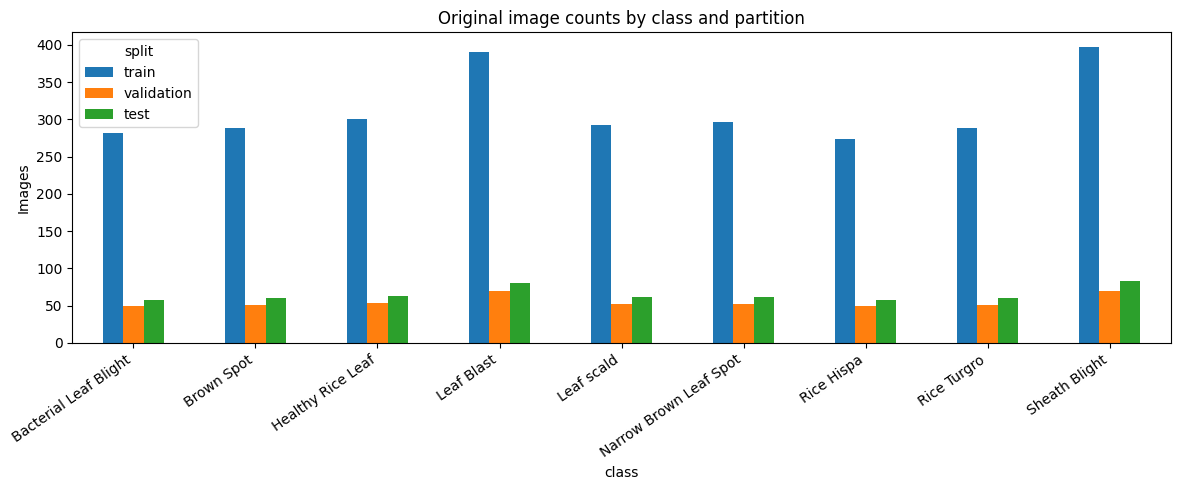

In [7]:
manifest = pd.read_csv(SPLIT_DIR / 'manifest.csv')
aug_manifest = pd.read_csv(AUG_DIR / 'manifest.csv')
classes = sorted(manifest['class'].unique().tolist())
class_to_idx = {name: i for i, name in enumerate(classes)}
assert manifest.path.is_unique and manifest.sha256.is_unique
assert set(manifest.split) == {'train', 'validation', 'test'}
train_originals = manifest[manifest.split == 'train']
assert set(aug_manifest.source_path) == set(train_originals.path)
assert aug_manifest.path.is_unique
assert aug_manifest.groupby('source_path').size().eq(4).all()
source_hashes = train_originals.set_index('path').sha256
assert aug_manifest.source_sha256.eq(aug_manifest.source_path.map(source_hashes)).all()
source_labels = train_originals.set_index('path')['class']
assert aug_manifest['class'].eq(aug_manifest.source_path.map(source_labels)).all()
for split in ['train', 'validation', 'test']:
    assert set(manifest.loc[manifest.split == split, 'class']) == set(classes)

weights = ResNet18_Weights.DEFAULT
preprocess = weights.transforms()  # ImageNet resize, center crop and normalization.

class ImageDataset(Dataset):
    def __init__(self, frame, base):
        self.frame = frame.reset_index(drop=True)
        self.base = base
        assert all((base / p).is_file() for p in self.frame.path), 'Run the data preparation notebook first.'

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]
        with Image.open(self.base / row['path']) as opened:
            image = ImageOps.exif_transpose(opened).convert('RGB')
            tensor = preprocess(image)
        return tensor, class_to_idx[row['class']]

train_dataset = ImageDataset(aug_manifest, AUG_DIR)
validation_dataset = ImageDataset(manifest[manifest.split == 'validation'], SPLIT_DIR / 'validation')
test_dataset = ImageDataset(manifest[manifest.split == 'test'], SPLIT_DIR / 'test')
generator = torch.Generator().manual_seed(SEED)
loader_options = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, pin_memory=DEVICE.type == 'cuda')
train_loader = DataLoader(train_dataset, shuffle=True, generator=generator, **loader_options)
validation_loader = DataLoader(validation_dataset, shuffle=False, **loader_options)
test_loader = DataLoader(test_dataset, shuffle=False, **loader_options)
print(f'Training: {len(train_dataset)} views ({len(train_originals)} original images)')
print(f'Validation: {len(validation_dataset)} | Test: {len(test_dataset)} | Classes: {len(classes)}')
counts = pd.crosstab(manifest['class'], manifest.split)[['train', 'validation', 'test']]
display(counts)
counts.plot.bar(figsize=(12, 5), rot=35, title='Original image counts by class and partition')
plt.ylabel('Images')
plt.xticks(ha='right')
plt.tight_layout()
plt.savefig(RUN_DIR / 'class_distribution.png', dpi=160)
plt.show()
counts.to_csv(RUN_DIR / 'class_distribution.csv')

## Build ResNet18 and the three-hidden-layer classifier

In [8]:
has_saved_model = (RUN_DIR / 'last_checkpoint.pt').exists() or (RUN_DIR / 'best_model.pt').exists()
model = resnet18(weights=None if has_saved_model else weights)
for parameter in model.parameters():
    parameter.requires_grad = False
if FINE_TUNE_LAST_BLOCK:
    for parameter in model.layer4.parameters():
        parameter.requires_grad = True

input_features = model.fc.in_features
model.fc = nn.Sequential(
    nn.Linear(input_features, 512), nn.ReLU(), nn.Dropout(0.5),
    nn.Linear(512, 256), nn.ReLU(), nn.Dropout(0.4),
    nn.Linear(256, 128), nn.ReLU(), nn.Dropout(0.3),
    nn.Linear(128, len(classes)),
)
model = model.to(DEVICE)
expected_prefixes = ('fc.', 'layer4.') if FINE_TUNE_LAST_BLOCK else ('fc.',)
assert all(p.requires_grad == name.startswith(expected_prefixes) for name, p in model.named_parameters())
parameter_groups = [{'params': model.fc.parameters(), 'lr': HEAD_LR}]
if FINE_TUNE_LAST_BLOCK:
    parameter_groups.append({'params': model.layer4.parameters(), 'lr': BACKBONE_LR})
optimizer = torch.optim.AdamW(parameter_groups, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=3)
criterion = nn.CrossEntropyLoss()
scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)
print(model.fc)
print('Trainable parameters:', sum(p.numel() for p in model.parameters() if p.requires_grad))
print('Total parameters:', sum(p.numel() for p in model.parameters()))
config = dict(seed=SEED, max_epochs=MAX_EPOCHS, patience=PATIENCE, batch_size=BATCH_SIZE,
              head_lr=HEAD_LR, backbone_lr=BACKBONE_LR, weight_decay=WEIGHT_DECAY,
              fine_tune_last_block=FINE_TUNE_LAST_BLOCK, hidden_layers=[512, 256, 128],
              classes=classes, class_to_idx=class_to_idx, weights=str(weights))
config['min_delta'] = MIN_DELTA
config['split_manifest_sha256'] = hashlib.sha256((SPLIT_DIR / 'manifest.csv').read_bytes()).hexdigest()
config['augmentation_manifest_sha256'] = hashlib.sha256((AUG_DIR / 'manifest.csv').read_bytes()).hexdigest()
config['augmentation_config_sha256'] = hashlib.sha256((AUG_DIR / 'config.json').read_bytes()).hexdigest()
config_path = RUN_DIR / 'config.json'
if config_path.exists():
    assert json.loads(config_path.read_text()) == config, 'Settings/data changed. Choose a new RUN_DIR.'
else:
    config_path.write_text(json.dumps(config, indent=2), encoding='utf-8')
(RUN_DIR / 'model_architecture.txt').write_text(str(model), encoding='utf-8')

Sequential(
  (0): Linear(in_features=512, out_features=512, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.5, inplace=False)
  (3): Linear(in_features=512, out_features=256, bias=True)
  (4): ReLU()
  (5): Dropout(p=0.4, inplace=False)
  (6): Linear(in_features=256, out_features=128, bias=True)
  (7): ReLU()
  (8): Dropout(p=0.3, inplace=False)
  (9): Linear(in_features=128, out_features=9, bias=True)
)
Trainable parameters: 428041
Total parameters: 11604553


5024

## Training and validation functions

In [9]:
def set_training_mode():
    # Keep the frozen CNN blocks and their BatchNorm statistics fixed.
    model.eval()
    model.fc.train()
    if FINE_TUNE_LAST_BLOCK:
        model.layer4.train()

def run_epoch(loader, training=False, verbose=1):
    if training:
        set_training_mode()
    else:
        model.eval()
    total_loss, correct, count = 0.0, 0, 0
    phase = "Train" if training else "Validation"
    for batch, (images, labels) in enumerate(loader, start=1):
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        if training:
            optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(training):
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                logits = model(images)
                loss = criterion(logits, labels)
            if training:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
        total_loss += loss.item() * labels.size(0)
        correct += (logits.argmax(1) == labels).sum().item()
        count += labels.size(0)
        if verbose:
            print(f"\r{phase} {batch}/{len(loader)} | loss {total_loss / count:.4f}, accuracy {correct / count:.4f}",
                  end="", flush=True)
    if verbose:
        print()
    return total_loss / count, correct / count

## Train once or load saved training

This cell automatically loads completed training. An interrupted run continues from its last
completed epoch, including optimizer, scheduler, early-stopping state, and PyTorch random states.
Weights and progress are saved after every epoch. Validation loss selects the best model.

In [10]:
checkpoint_path = RUN_DIR / 'best_model.pt'
last_path = RUN_DIR / 'last_checkpoint.pt'
history = []
best_loss = float('inf')
best_epoch = 0
epochs_without_improvement = 0
start_epoch = 1
training_complete = False

def atomic_save(payload, path):
    temporary = path.with_suffix(path.suffix + '.tmp')
    torch.save(payload, temporary)
    temporary.replace(path)

if last_path.exists():
    saved = torch.load(last_path, map_location=DEVICE, weights_only=True)
    assert saved['config'] == config, 'Settings/data changed. Choose a new RUN_DIR for a new experiment.'
    history = saved['history']
    best_loss, best_epoch = saved['best_loss'], saved['best_epoch']
    epochs_without_improvement = saved['epochs_without_improvement']
    start_epoch = saved['epoch'] + 1
    training_complete = saved['training_complete']
    if not training_complete:
        model.load_state_dict(saved['model_state_dict'])
        optimizer.load_state_dict(saved['optimizer_state_dict'])
        scheduler.load_state_dict(saved['scheduler_state_dict'])
        # Older CPU checkpoints have no scaler state and can still be resumed.
        if USE_AMP and saved.get('scaler_state_dict'):
            scaler.load_state_dict(saved['scaler_state_dict'])
        torch.set_rng_state(saved['torch_rng_state'].cpu())
        generator.set_state(saved['loader_rng_state'].cpu())
        if torch.cuda.is_available() and saved['cuda_rng_state'] is not None:
            torch.cuda.set_rng_state_all([s.cpu() for s in saved['cuda_rng_state']])
        print(f'Continuing from epoch {start_epoch}; completed epochs are preserved.')
    else:
        print('Completed training found. Loading saved weights and history; training skipped.')
elif checkpoint_path.exists():
    raise RuntimeError('An older best_model.pt exists without a last checkpoint. Use a new RUN_DIR to train; existing weights are preserved.')

if not training_complete:
    for epoch in range(start_epoch, MAX_EPOCHS + 1):
        print(f"Epoch {epoch:03d}/{MAX_EPOCHS}", flush=True)
        started = time.time()
        head_lr = optimizer.param_groups[0]['lr']
        train_loss, train_acc = run_epoch(train_loader, training=True)
        val_loss, val_acc = run_epoch(validation_loader)
        if not np.isfinite([train_loss, val_loss]).all():
            raise RuntimeError('Non-finite loss; check inputs and learning rate.')
        scheduler.step(val_loss)
        history.append(dict(epoch=epoch, train_loss=train_loss, validation_loss=val_loss,
                            train_accuracy=train_acc, validation_accuracy=val_acc,
                            head_lr=head_lr, seconds=time.time() - started))
        print(f'Epoch {epoch:03d}/{MAX_EPOCHS} | train loss {train_loss:.4f}, accuracy {train_acc:.4f}'
              f' | validation loss {val_loss:.4f}, accuracy {val_acc:.4f}')
        if val_loss < best_loss - MIN_DELTA:
            best_loss, best_epoch = val_loss, epoch
            epochs_without_improvement = 0
            atomic_save({'model_state_dict': model.state_dict(), 'epoch': epoch,
                         'validation_loss': val_loss, 'class_to_idx': class_to_idx,
                         'config': config}, checkpoint_path)
        else:
            epochs_without_improvement += 1
        training_complete = epochs_without_improvement >= PATIENCE or epoch == MAX_EPOCHS
        atomic_save({'model_state_dict': model.state_dict(), 'optimizer_state_dict': optimizer.state_dict(),
                     'scheduler_state_dict': scheduler.state_dict(),
                     'scaler_state_dict': scaler.state_dict(), 'epoch': epoch,
                     'history': history, 'best_loss': best_loss, 'best_epoch': best_epoch,
                     'epochs_without_improvement': epochs_without_improvement,
                     'training_complete': training_complete, 'config': config,
                     'torch_rng_state': torch.get_rng_state(), 'loader_rng_state': generator.get_state(),
                     'cuda_rng_state': torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None}, last_path)
        pd.DataFrame(history).to_csv(RUN_DIR / 'history.csv', index=False)
        (RUN_DIR / 'training_log.txt').write_text(pd.DataFrame(history).to_string(index=False), encoding='utf-8')
        if training_complete:
            print('Early stopping reached.' if epochs_without_improvement >= PATIENCE else 'Maximum epochs reached.')
            break

pd.DataFrame(history).to_csv(RUN_DIR / 'history.csv', index=False)
checkpoint = torch.load(checkpoint_path, map_location=DEVICE, weights_only=True)
assert checkpoint['class_to_idx'] == class_to_idx
assert checkpoint['config'] == config
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()
atomic_save(model.state_dict(), RUN_DIR / 'best_weights.pth')
print(f'Restored best epoch {checkpoint["epoch"]}, validation loss {checkpoint["validation_loss"]:.4f}')

Continuing from epoch 5; completed epochs are preserved.
Epoch 005/100
Train 352/352 | loss 0.7808, accuracy 0.7095
Validation 16/16 | loss 0.7524, accuracy 0.7143
Epoch 005/100 | train loss 0.7808, accuracy 0.7095 | validation loss 0.7524, accuracy 0.7143
Epoch 006/100
Train 352/352 | loss 0.7477, accuracy 0.7240
Validation 16/16 | loss 0.7434, accuracy 0.7404
Epoch 006/100 | train loss 0.7477, accuracy 0.7240 | validation loss 0.7434, accuracy 0.7404
Epoch 007/100
Train 352/352 | loss 0.7148, accuracy 0.7384
Validation 16/16 | loss 0.7306, accuracy 0.7223
Epoch 007/100 | train loss 0.7148, accuracy 0.7384 | validation loss 0.7306, accuracy 0.7223
Epoch 008/100
Train 352/352 | loss 0.6852, accuracy 0.7480
Validation 16/16 | loss 0.7050, accuracy 0.7425
Epoch 008/100 | train loss 0.6852, accuracy 0.7480 | validation loss 0.7050, accuracy 0.7425
Epoch 009/100
Train 352/352 | loss 0.6692, accuracy 0.7539
Validation 16/16 | loss 0.7099, accuracy 0.7243
Epoch 009/100 | train loss 0.6692, a

## Learning curves and learning rate

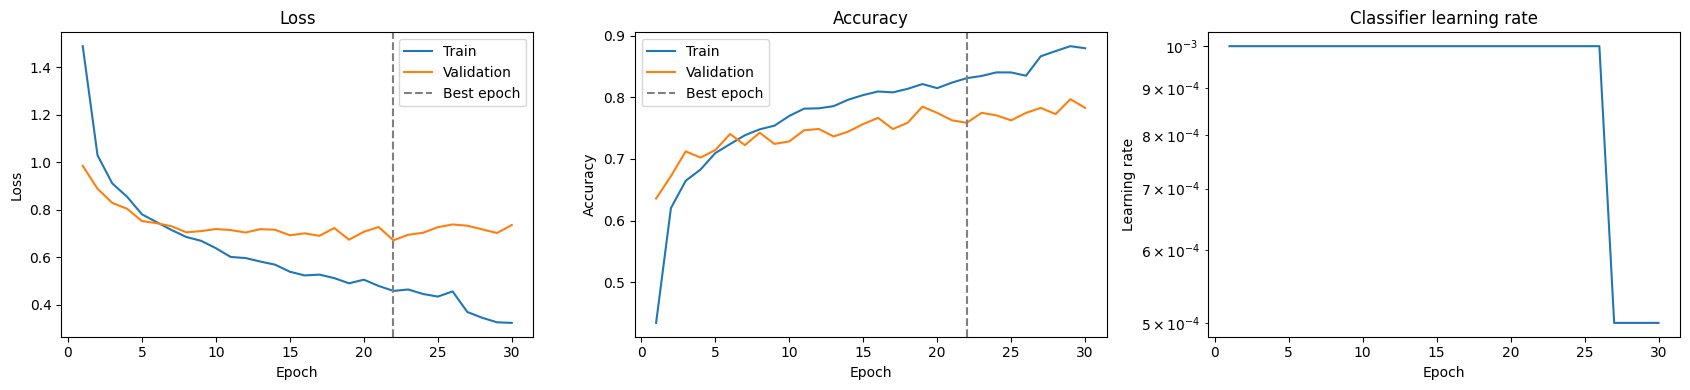

In [11]:
history_df = pd.DataFrame(history)
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for column, title, ax in [('loss', 'Loss', axes[0]), ('accuracy', 'Accuracy', axes[1])]:
    ax.plot(history_df.epoch, history_df[f'train_{column}'], label='Train')
    ax.plot(history_df.epoch, history_df[f'validation_{column}'], label='Validation')
    ax.axvline(checkpoint['epoch'], color='gray', linestyle='--', label='Best epoch')
    ax.set(title=title, xlabel='Epoch', ylabel=title)
    ax.legend()
axes[2].plot(history_df.epoch, history_df.head_lr)
axes[2].set(title='Classifier learning rate', xlabel='Epoch', ylabel='Learning rate', yscale='log')
plt.tight_layout()
plt.savefig(RUN_DIR / 'learning_curves.png', dpi=180)
plt.show()

## Evaluate the best model on the held-out test set

In [12]:
prediction_cache = RUN_DIR / 'test_outputs.npz'
model_digest = hashlib.sha256(checkpoint_path.read_bytes()).hexdigest()
if prediction_cache.exists():
    with np.load(prediction_cache, allow_pickle=False) as saved_outputs:
        cache_matches = saved_outputs['model_sha256'].item() == model_digest
        if cache_matches:
            y_true = saved_outputs['y_true'].copy()
            probabilities = saved_outputs['probabilities'].copy()
            test_loss_sum = float(saved_outputs['test_loss_sum'].item())
    if cache_matches:
        print('Loaded saved test predictions; inference skipped.')
else:
    cache_matches = False
if not cache_matches:
    all_labels, all_probabilities = [], []
    test_loss_sum = 0.0
    model.eval()
    with torch.inference_mode():
        for images, labels in test_loader:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)
            logits = model(images)
            test_loss_sum += criterion(logits, labels).item() * labels.size(0)
            all_labels.extend(labels.cpu().numpy())
            all_probabilities.append(logits.softmax(dim=1).cpu().numpy())
    y_true = np.asarray(all_labels)
    probabilities = np.concatenate(all_probabilities)
    temporary = prediction_cache.with_suffix('.tmp.npz')
    np.savez_compressed(temporary, y_true=y_true, probabilities=probabilities,
                        test_loss_sum=test_loss_sum, model_sha256=model_digest)
    temporary.replace(prediction_cache)
y_pred = probabilities.argmax(axis=1)
label_ids = list(range(len(classes)))
precision, recall, f1, _ = precision_recall_fscore_support(
    y_true, y_pred, labels=label_ids, average='macro', zero_division=0)
metrics = {'test_loss': test_loss_sum / len(test_dataset),
           'accuracy': float(accuracy_score(y_true, y_pred)), 'macro_precision': float(precision),
           'macro_recall': float(recall), 'macro_f1': float(f1), 'best_epoch': checkpoint['epoch']}
print(json.dumps(metrics, indent=2))
report = classification_report(y_true, y_pred, labels=label_ids, target_names=classes,
                               output_dict=True, zero_division=0)
report_df = pd.DataFrame(report).transpose()
display(report_df)
report_df.to_csv(RUN_DIR / 'classification_report.csv')
(RUN_DIR / 'test_metrics.json').write_text(json.dumps(metrics, indent=2), encoding='utf-8')
predictions = test_dataset.frame[['path', 'class']].copy()
predictions['predicted_class'] = [classes[i] for i in y_pred]
predictions['confidence'] = probabilities.max(axis=1)
for i, name in enumerate(classes):
    predictions[f'probability_{name}'] = probabilities[:, i]
predictions.to_csv(RUN_DIR / 'test_predictions.csv', index=False)

{
  "test_loss": 0.6177992826353197,
  "accuracy": 0.7876712328767124,
  "macro_precision": 0.7968201885255624,
  "macro_recall": 0.7875569045461119,
  "macro_f1": 0.7884185853516961,
  "best_epoch": 22
}


,precision,recall,f1-score,support
Bacterial Leaf Blight,0.862069,0.862069,0.862069,58.000000
Brown Spot,0.795455,0.583333,0.673077,60.000000
Healthy Rice Leaf,0.814286,0.904762,0.857143,63.000000
Leaf Blast,0.736264,0.827160,0.779070,81.000000
Leaf scald,0.527027,0.639344,0.577778,61.000000
Narrow Brown Leaf Spot,0.846154,0.721311,0.778761,61.000000
Rice Hispa,0.866667,0.912281,0.888889,57.000000
Rice Turgro,0.881356,0.866667,0.873950,60.000000
Sheath Blight,0.842105,0.771084,0.805031,83.000000
accuracy,0.787671,0.787671,0.787671,0.787671


## Confusion matrices and per-class scores

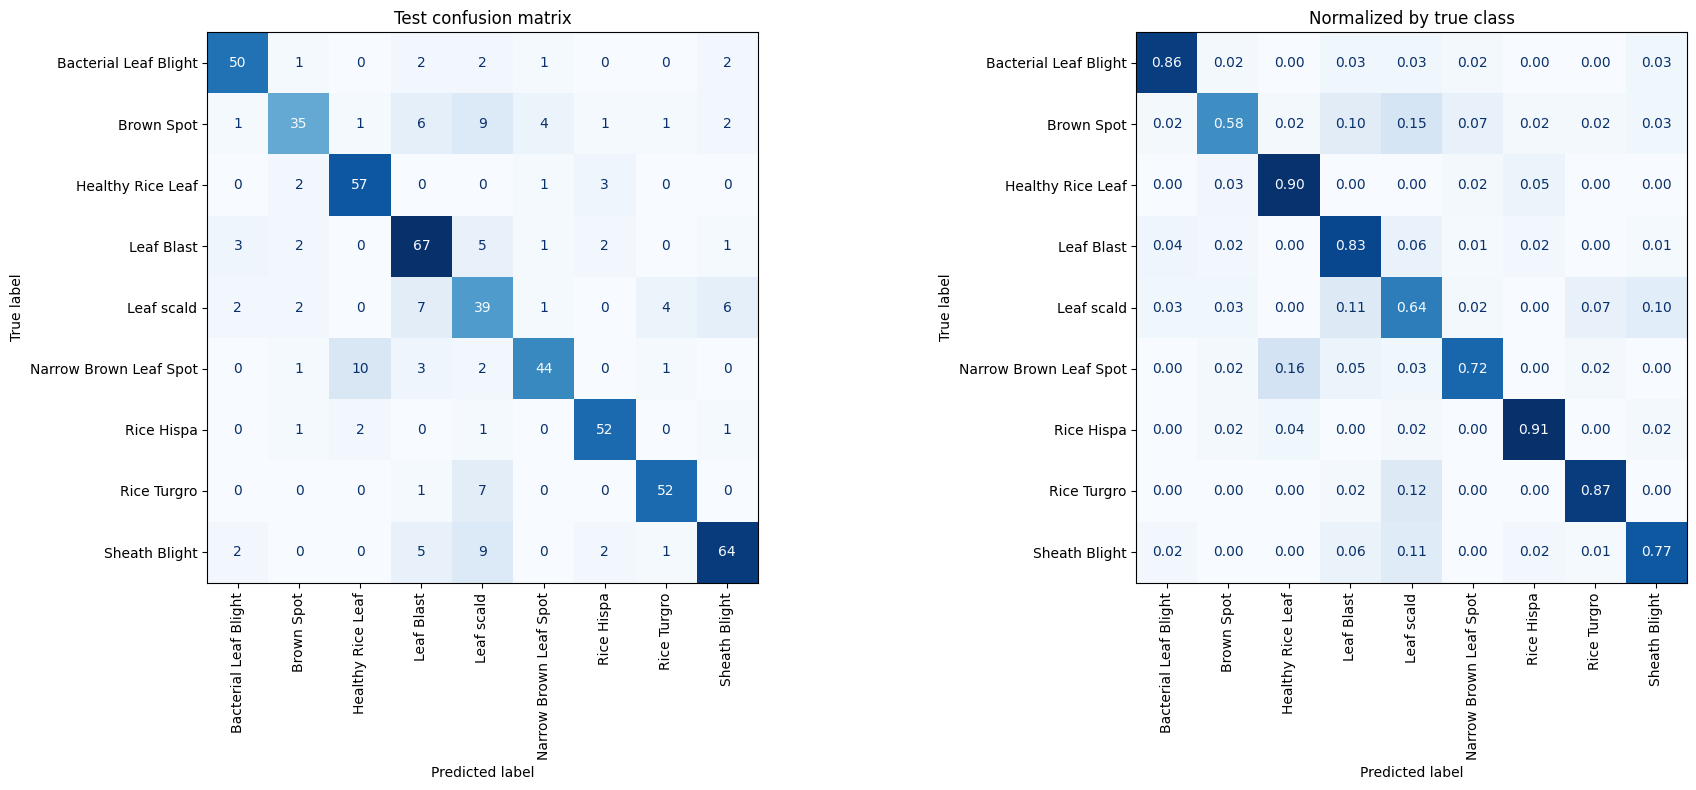

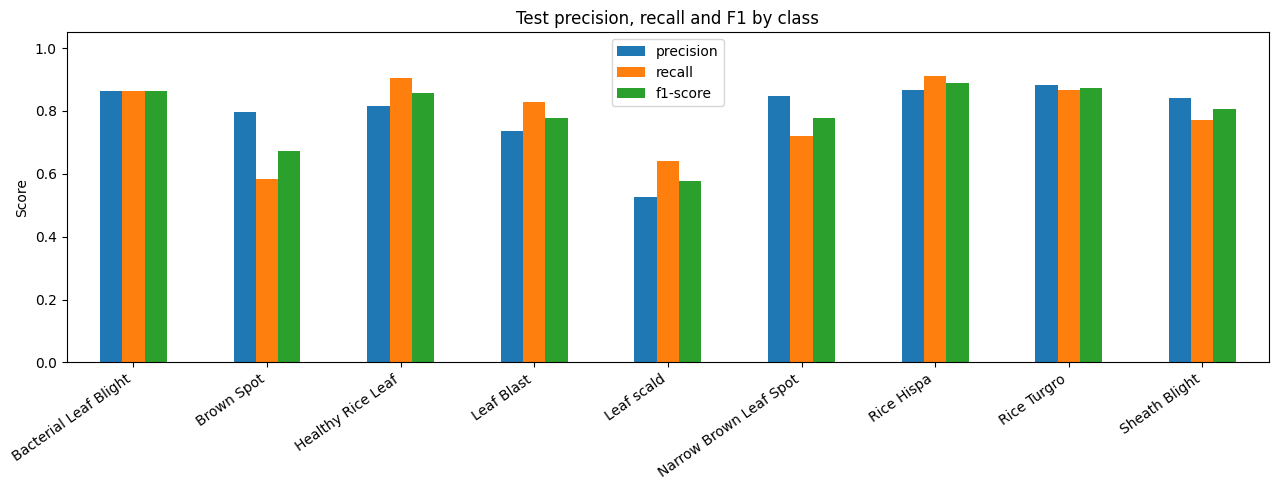

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(19, 8))
for ax, normalization, title in zip(axes, [None, 'true'], ['Test confusion matrix', 'Normalized by true class']):
    matrix = confusion_matrix(y_true, y_pred, labels=label_ids, normalize=normalization)
    csv_name = 'confusion_matrix_normalized.csv' if normalization else 'confusion_matrix.csv'
    pd.DataFrame(matrix, index=classes, columns=classes).to_csv(RUN_DIR / csv_name)
    ConfusionMatrixDisplay(matrix, display_labels=classes).plot(
        ax=ax, cmap='Blues', colorbar=False, xticks_rotation=90,
        values_format='.2f' if normalization else 'd')
    ax.set_title(title)
plt.tight_layout()
plt.savefig(RUN_DIR / 'confusion_matrices.png', dpi=180)
plt.show()

report_df.loc[classes, ['precision', 'recall', 'f1-score']].plot.bar(figsize=(13, 5), rot=35)
plt.ylim(0, 1.05)
plt.ylabel('Score')
plt.title('Test precision, recall and F1 by class')
plt.xticks(ha='right')
plt.tight_layout()
plt.savefig(RUN_DIR / 'per_class_scores.png', dpi=180)
plt.show()

## Inspect test errors

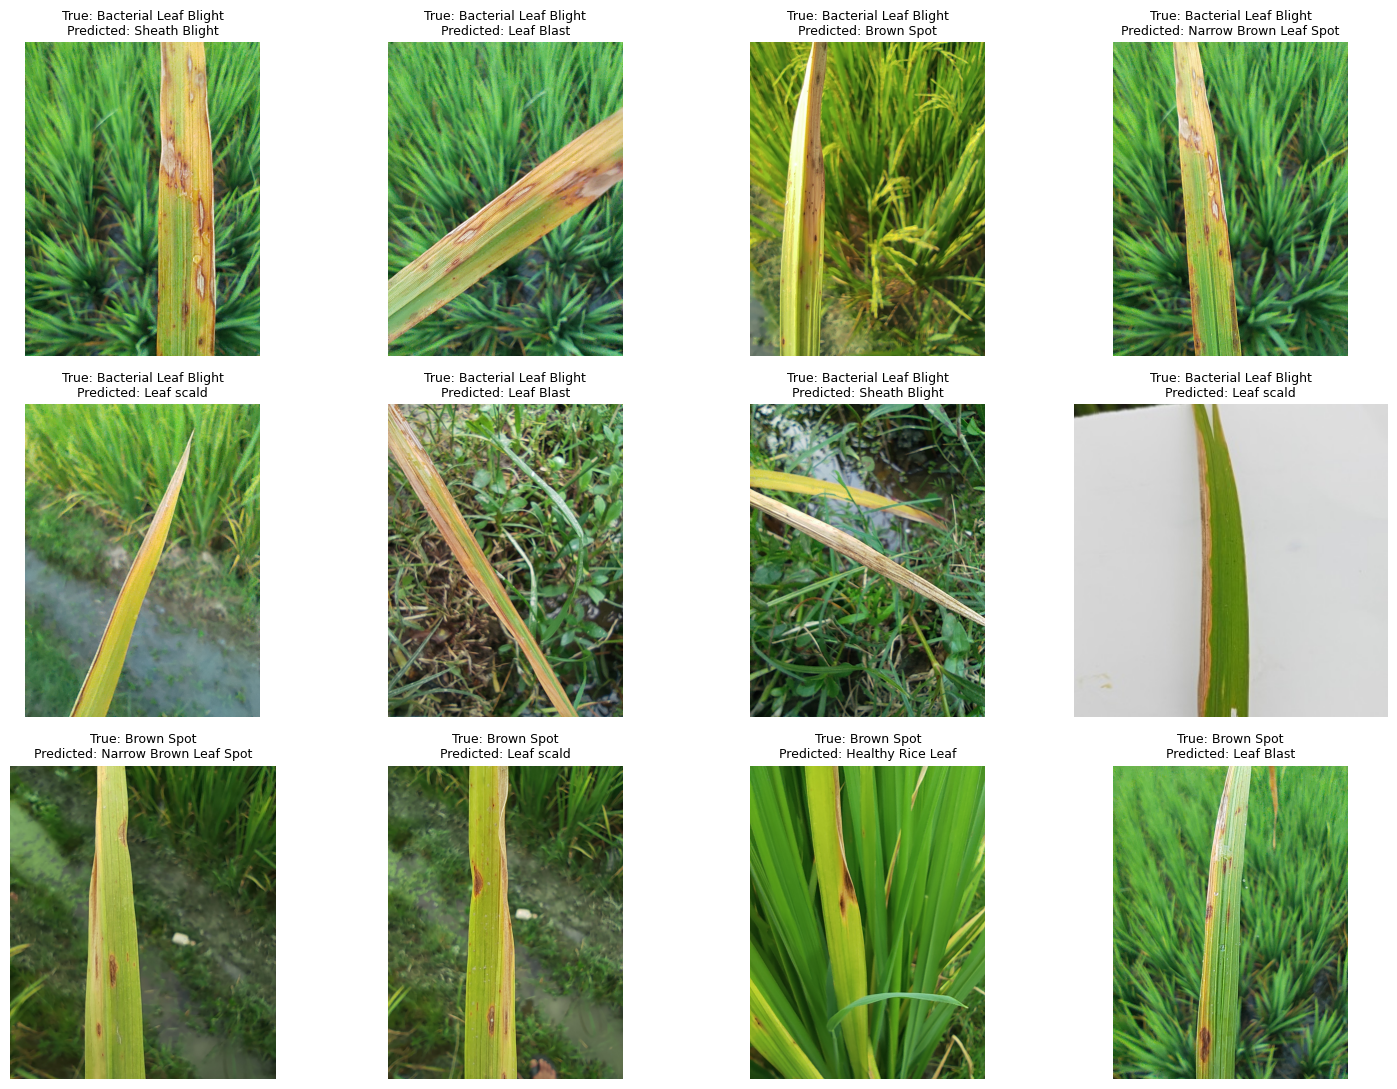

Saved checkpoint, metrics, predictions and plots to: C:\Users\Anuradha\Documents\Final-Year-Project\Final-Year-Project\results\resnet18_frozen


In [14]:
wrong_indices = np.flatnonzero(y_true != y_pred)[:12]
if len(wrong_indices):
    fig, axes = plt.subplots(3, 4, figsize=(15, 11))
    for ax in axes.flat:
        ax.axis('off')
    for ax, index in zip(axes.flat, wrong_indices):
        path = test_dataset.base / test_dataset.frame.iloc[index]['path']
        with Image.open(path) as image:
            ax.imshow(ImageOps.exif_transpose(image).convert('RGB'))
        ax.set_title(f'True: {classes[y_true[index]]}\nPredicted: {classes[y_pred[index]]}', fontsize=9)
    plt.tight_layout()
    plt.savefig(RUN_DIR / 'test_errors.png', dpi=160)
    plt.show()
else:
    print('No misclassified test images.')
(RUN_DIR / 'test_errors.txt').write_text(f'Total test errors: {int((y_true != y_pred).sum())}', encoding='utf-8')
print('Saved checkpoint, metrics, predictions and plots to:', RUN_DIR)

## Save a standalone results report

Open `report.html` later to inspect outputs without rerunning the notebook.

In [15]:
import base64
import html
from IPython.display import FileLink

sections = ['<!doctype html><html><head><meta charset="utf-8"><title>ResNet18 results</title>',
            '<style>body{font:16px Arial;max-width:1200px;margin:40px auto;padding:20px}img{max-width:100%}table{border-collapse:collapse}td,th{border:1px solid #ccc;padding:8px}pre{white-space:pre-wrap}</style>',
            '</head><body>', f'<h1>{html.escape(RUN_DIR.name)}</h1>',
            '<h2>Test metrics</h2>', f'<pre>{html.escape(json.dumps(metrics, indent=2))}</pre>',
            '<h2>Classification report</h2>', report_df.to_html(),
            '<h2>Training configuration</h2>', f'<pre>{html.escape(json.dumps(config, indent=2))}</pre>',
            '<h2>Training history</h2>', pd.DataFrame(history).to_html(index=False)]
plots = ['class_distribution.png', 'learning_curves.png', 'confusion_matrices.png', 'per_class_scores.png']
if len(wrong_indices):
    plots.append('test_errors.png')
for filename in plots:
    plot = RUN_DIR / filename
    encoded = base64.b64encode(plot.read_bytes()).decode('ascii')
    sections.append(f'<h2>{html.escape(plot.stem.replace("_", " "))}</h2><img src="data:image/png;base64,{encoded}">')
sections.append('</body></html>')
report_path = RUN_DIR / 'report.html'
temporary = report_path.with_suffix('.tmp.html')
temporary.write_text('\n'.join(sections), encoding='utf-8')
temporary.replace(report_path)
print('All results saved. Open this report later; no training is needed:')
display(FileLink(str(report_path.relative_to(ROOT))))

All results saved. Open this report later; no training is needed:


c:\Users\Anuradha\Documents\Final-Year-Project\Final-Year-Project\results\resnet18_frozen\report.html

In [16]:
# Record the actual environment and package the complete experiment for transfer.
import platform
from importlib.metadata import version, PackageNotFoundError
import shutil

environment = {'python': platform.python_version(), 'platform': platform.platform(),
               'device': str(DEVICE), 'cuda_runtime': torch.version.cuda,
               'mixed_precision': USE_AMP, 'num_workers': NUM_WORKERS,
               'gpu': torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
               'packages': {}}
for package in ['torch', 'torchvision', 'numpy', 'pandas', 'matplotlib',
                'Pillow', 'scikit-learn', 'ipython', 'ipykernel']:
    try:
        environment['packages'][package] = version(package)
    except PackageNotFoundError:
        environment['packages'][package] = 'not installed'
(RUN_DIR / 'environment.json').write_text(json.dumps(environment, indent=2), encoding='utf-8')
archive = shutil.make_archive(str(RUN_DIR.parent / (RUN_DIR.name + '_results')), 'zip',
                              root_dir=RUN_DIR.parent, base_dir=RUN_DIR.name)
print('Copy this archive back for analysis and further development:', archive)
display(FileLink(str(Path(archive).relative_to(ROOT))))


Copy this archive back for analysis and further development: C:\Users\Anuradha\Documents\Final-Year-Project\Final-Year-Project\results\resnet18_frozen_results.zip


c:\Users\Anuradha\Documents\Final-Year-Project\Final-Year-Project\results\resnet18_frozen_results.zip